In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
#data download:
#!/bin/bash
!kaggle datasets download -d arwabasal/brain-tumor-mri-detection

Dataset URL: https://www.kaggle.com/datasets/arwabasal/brain-tumor-mri-detection
License(s): MIT
100% 15.1M/15.1M [00:01<00:00, 8.74MB/s]



In [ ]:
#unzip:
import zipfile
zip_ref = zipfile.ZipFile('/content/brain-tumor-mri-detection.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
#loading libraries:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,BatchNormalization,Dense,Flatten, Dropout,GlobalAveragePooling2D, MaxPooling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow import keras
from matplotlib import pyplot as plt
from tensorflow.keras.regularizers import l1, l2

In [ ]:
#generators:
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/brain_tumor_dataset",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "training",
    seed = 123
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/brain_tumor_dataset",
    labels = "inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (256,256),
    validation_split = 0.2,
    subset = "validation",
    seed = 123
)


Found 253 files belonging to 2 classes.
Using 203 files for training.
Found 253 files belonging to 2 classes.
Using 50 files for validation.


In [ ]:
# normalization:
def process(image,label):
  image = tf.cast(image/255., tf.float32)
  return image, label
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [ ]:
#cnn architecture:
model = Sequential()

#input layer:
model.add(Conv2D(32,kernel_size=(3,3),padding = "same", activation = "relu", kernel_regularizer=l2(0.002),input_shape = (256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides = 2, padding = "same"))

#hidden layer 1:
model.add(Conv2D(64,kernel_size=(3,3), padding = "same", kernel_regularizer=l2(0.002), activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides = 2, padding = "same"))

#hidden layer 2:
model.add(Conv2D(128,kernel_size=(3,3), padding = "same", kernel_regularizer=l2(0.002), activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides = 2, padding = "same"))

#hidden layer 3:
model.add(Conv2D(128,kernel_size=(3,3), padding = "same", kernel_regularizer=l2(0.002),activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides = 2, padding = "same"))

#flatten:
model.add(Flatten())

# globalaverage = gives average
#dense layer:
model.add(Dense(128, activation = "relu"))
model.add(Dropout(0.5))

#output:
model.add(Dense(1,activation="sigmoid"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,801 (16.93 MB)

 Trainable params: 4,436,097 (16.92 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
#compile:
model.compile(optimizer="adam", loss = "binary_crossentropy", metrics = ["accuracy"])

In [ ]:
early_stopping= EarlyStopping(monitor="val_loss", patience=5,restore_best_weights=True)

In [ ]:
#training:
history = model.fit(train_ds, epochs = 60, validation_data= validation_ds, callbacks= [early_stopping])

Epoch 1/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 164ms/step - accuracy: 0.8670 - loss: 0.8666 - val_accuracy: 0.7200 - val_loss: 1.5275
Epoch 2/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.8818 - loss: 0.8382 - val_accuracy: 0.6600 - val_loss: 1.6223
Epoch 3/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.9064 - loss: 0.7665 - val_accuracy: 0.6000 - val_loss: 1.8885
Epoch 4/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.9261 - loss: 0.7257 - val_accuracy: 0.5000 - val_loss: 2.7265
Epoch 5/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.9113 - loss: 0.7182 - val_accuracy: 0.3800 - val_loss: 3.1471


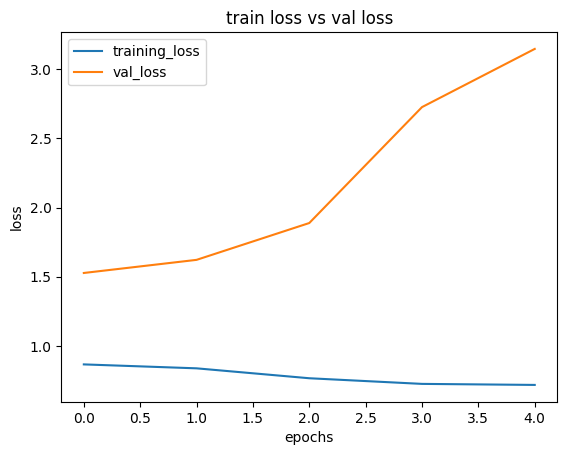

In [ ]:
# graph:
plt.plot(history.history["loss"],label="training_loss")
plt.plot(history.history["val_loss"],label = "val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

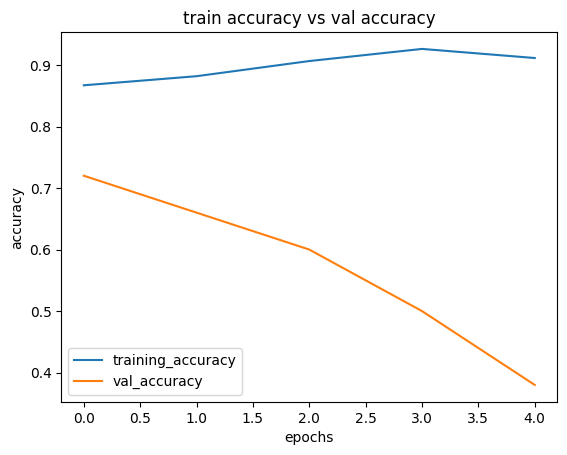

In [ ]:
# graph:
plt.plot(history.history["accuracy"],label="training_accuracy")
plt.plot(history.history["val_accuracy"],label = "val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()